# 04 — Muestras por clase objetivo

**Etapa I (PPS) / F2.** Para cada clase objetivo se extrae el **segmento de ritmo más largo**
(pediátrico; caída a adultos solo si el pediátrico no alcanza para una ventana de 12 s) y se
grafican 10 s de las 12 derivaciones. El filtrado (paso-alto 0.5 Hz, paso-bajo 100 Hz, notch
50 Hz, `sosfiltfilt`) es **solo para visualización**; el diseño formal de filtros es F4.

In [1]:
%matplotlib inline
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(os.environ.get('PROJECT_ROOT',
                           Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
RES = ROOT / 'results'
FIG = RES / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(2026)

import wfdb
from scipy import signal

DATA = ROOT / 'data' / ('leipzig-heart-center-ecg-database-arrhythmias-in-children-'
                        'and-patients-with-congenital-heart-disease-1.0.0')
SURFACE = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


def segmentos(name):
    h = wfdb.rdheader(str(DATA / name))
    ann = wfdb.rdann(str(DATA / name), 'atr')
    idx = [i for i, (s, a) in enumerate(zip(ann.symbol, ann.aux_note)) if s == '+' and a]
    out = []
    for j, i in enumerate(idx):
        fin = ann.sample[idx[j + 1]] if j + 1 < len(idx) else h.sig_len
        out.append((ann.aux_note[i].strip(), ann.sample[i], fin))
    return out


ritmos = pd.read_csv(RES / 'inventario' / 'ritmos.csv')
CLASE = {'(N': 'Sinusal', '(AVRT': 'SVT', '(AVNRT': 'SVT', '(EAT': 'SVT', '(A': 'SVT', '(J': 'SVT',
         '(AFIB': 'SVT', '(VT': 'VT', '(IVR': 'VT', '(AFL': 'AFL', '(/A': 'Paced', '(/V': 'Paced'}

elegidos = []
for clase in ['Sinusal', 'SVT', 'Paced', 'VT', 'AFL']:
    cand = []
    for grupo in ['pediatrico', 'adulto']:
        regs = ritmos.loc[(ritmos.clase == clase) & (ritmos.grupo == grupo), 'registro'].unique()
        for name in regs:
            for ritmo, ini, fin in segmentos(name):
                if CLASE.get(ritmo) == clase:
                    cand.append((grupo, name, ritmo, ini, (fin - ini) / 977))
        if grupo == 'pediatrico' and max([c[4] for c in cand], default=0) >= 12:
            break  # ya hay segmento pediátrico suficiente
    cand.sort(key=lambda c: c[4], reverse=True)
    g, name, ritmo, ini, dur = cand[0]
    elegidos.append({'clase': clase, 'grupo': g, 'registro': name, 'ritmo_wfdb': ritmo,
                     'duracion_s': round(dur, 1), 'inicio_s': round(ini / 977, 1)})
elegidos = pd.DataFrame(elegidos)
elegidos


,clase,grupo,registro,ritmo_wfdb,duracion_s,inicio_s
0,Sinusal,pediatrico,x001,(N,3305.4,96.2
1,SVT,pediatrico,x0011,(AVRT,613.7,21.8
2,Paced,pediatrico,x009,(/A,634.4,200.7
3,VT,pediatrico,x002,(VT,15.6,2769.4
4,AFL,pediatrico,x006,(AFL,37.3,2115.6


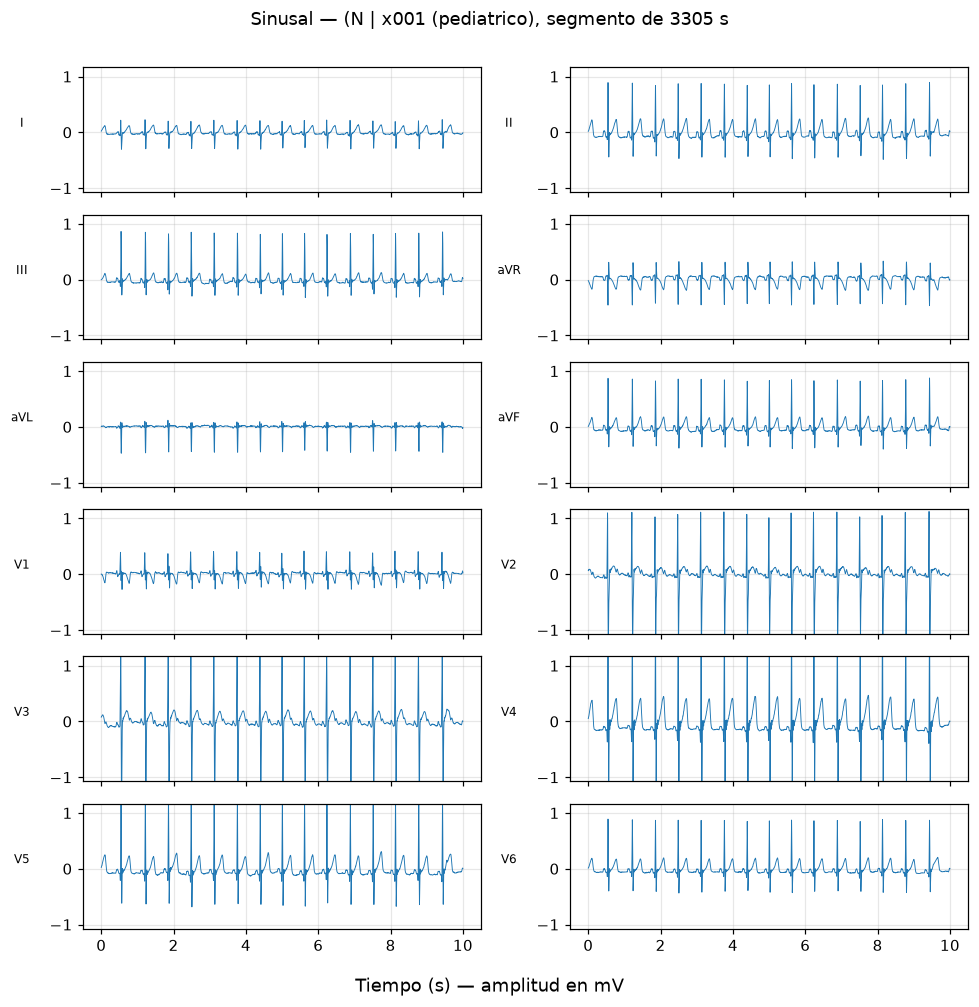

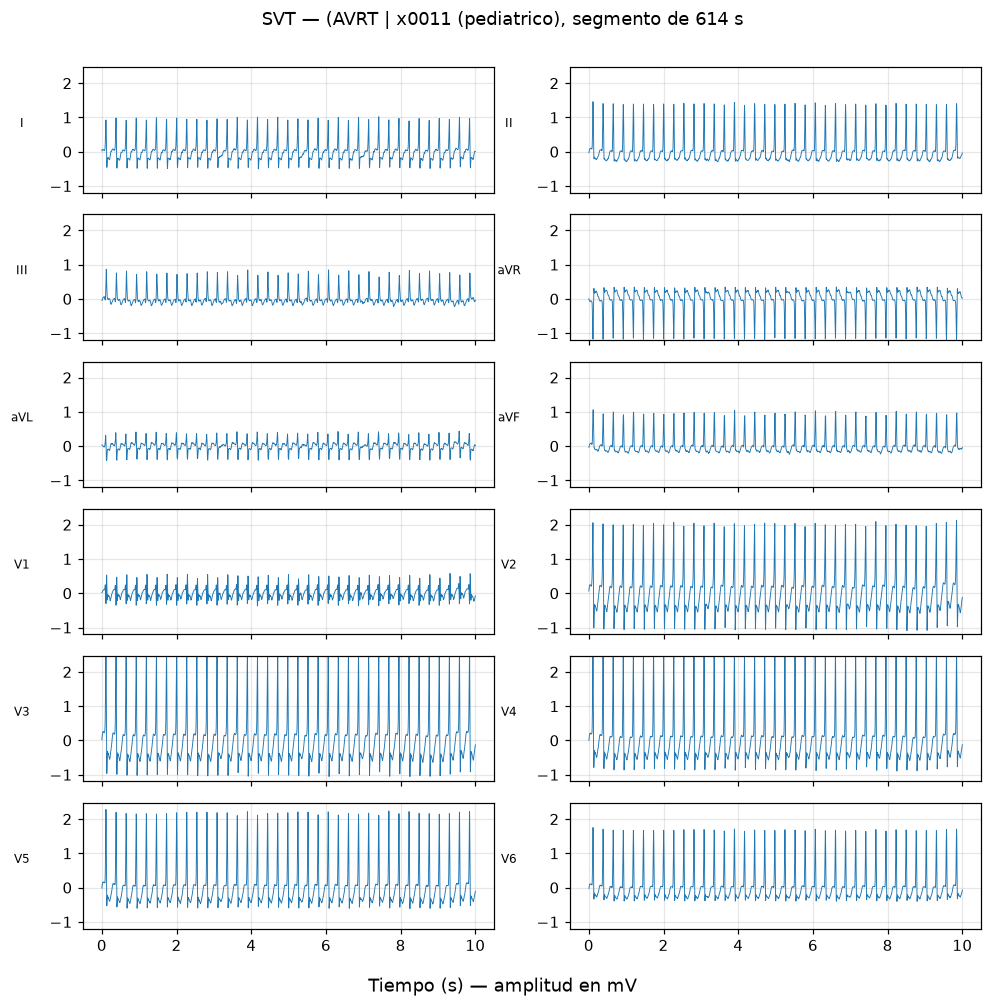

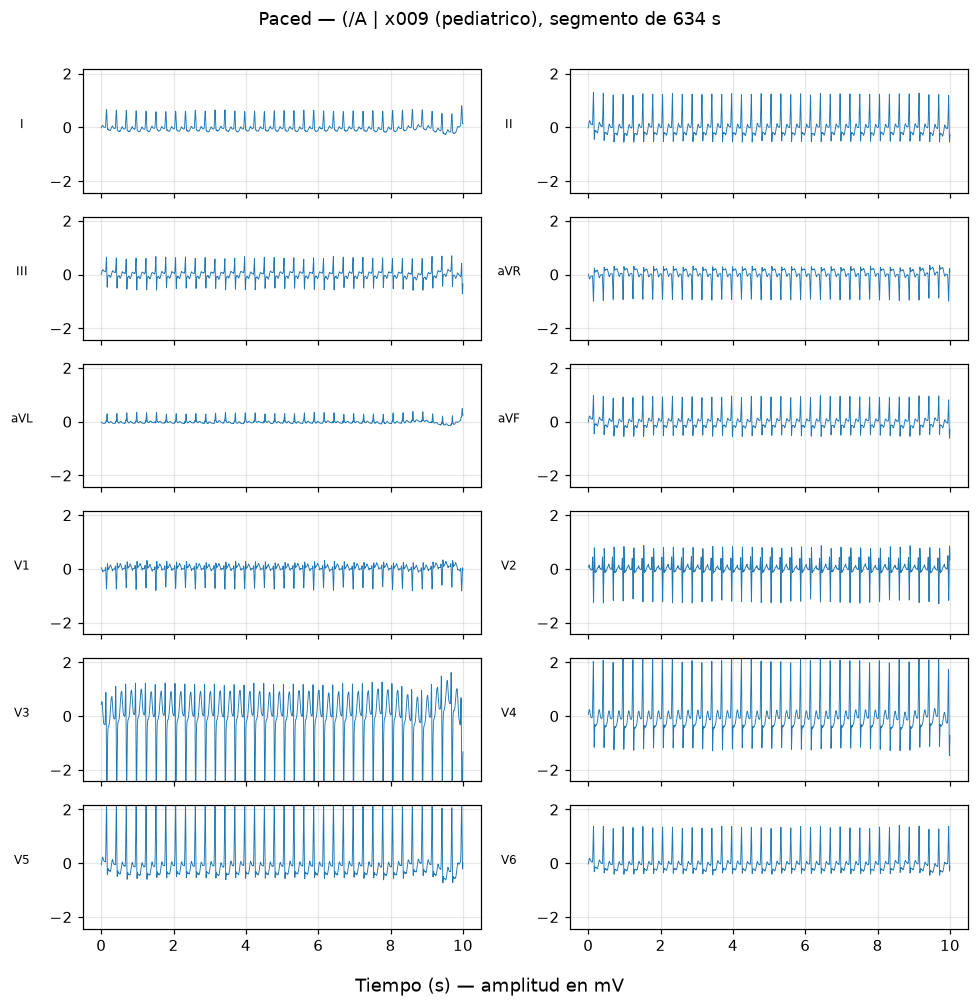

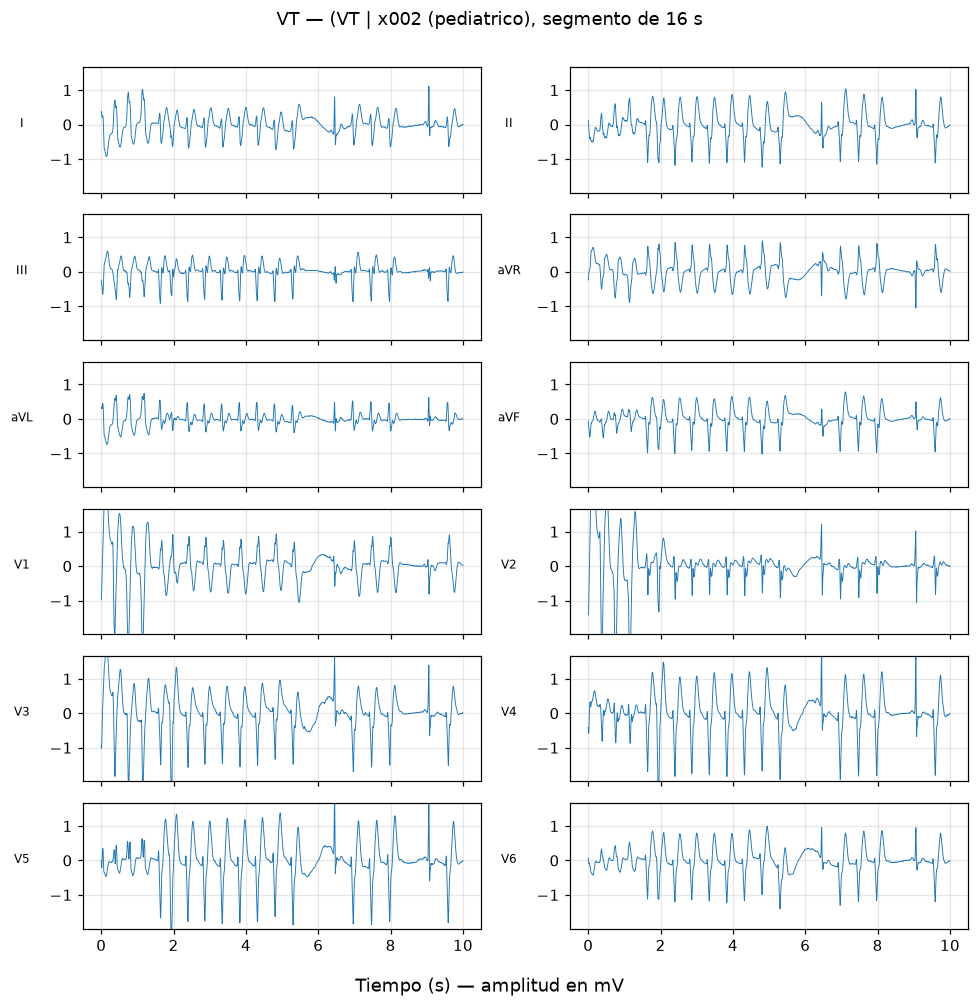

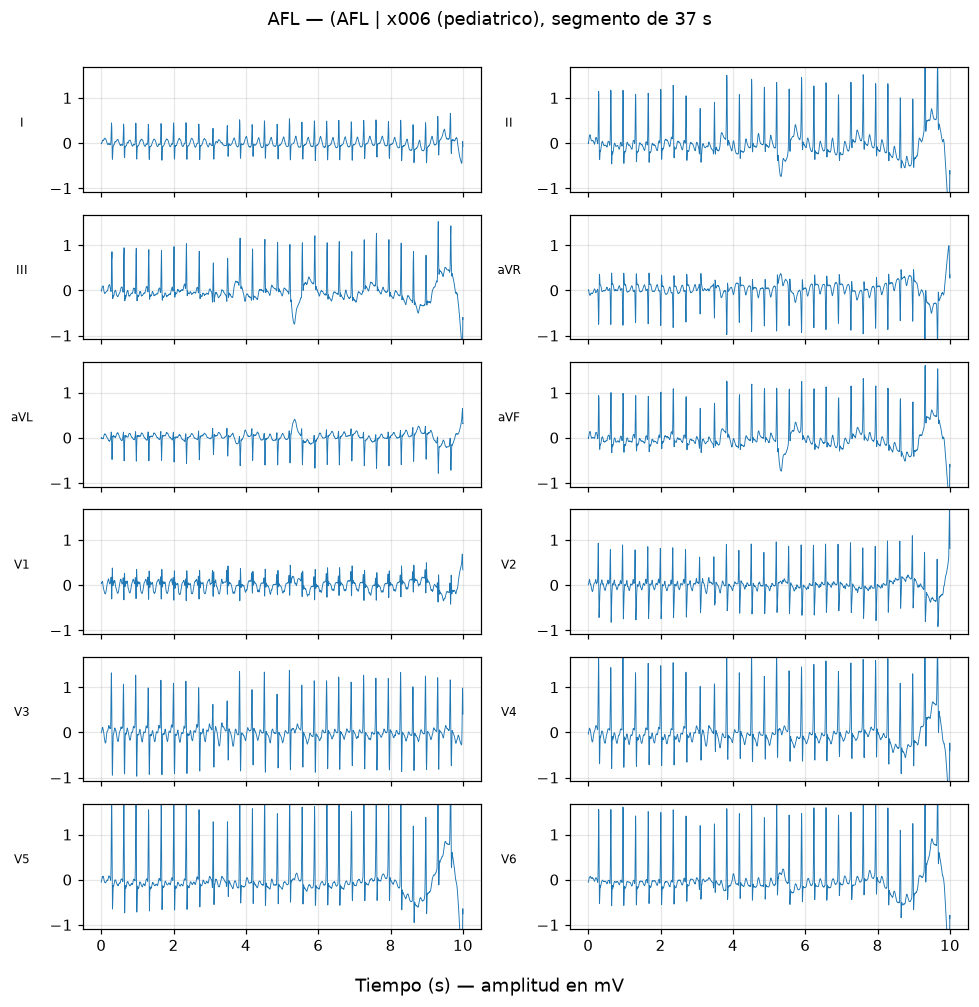

In [2]:
def ventana_filtrada(name, centro_s, fs_w=10):
    h = wfdb.rdheader(str(DATA / name))
    ch = [h.sig_name.index(s) for s in SURFACE]
    ini = int(np.clip(centro_s * h.fs - fs_w * h.fs / 2, 0, h.sig_len - fs_w * h.fs))
    r = wfdb.rdrecord(str(DATA / name), sampfrom=ini, sampto=ini + fs_w * h.fs, channels=ch, physical=True)
    x, fs = r.p_signal, r.fs
    sos_hp = signal.butter(4, 0.5, 'hp', fs=fs, output='sos')
    sos_lp = signal.butter(4, 100, 'lp', fs=fs, output='sos')
    b, a = signal.iirnotch(50, Q=35, fs=fs)
    x = signal.sosfiltfilt(sos_hp, x, axis=0)
    x = signal.sosfiltfilt(sos_lp, x, axis=0)
    x = signal.filtfilt(b, a, x, axis=0)
    return x, fs, r.units[0]


for _, fila in elegidos.iterrows():
    x, fs, unidad = ventana_filtrada(fila.registro, fila.inicio_s + fila.duracion_s / 2)
    t = np.arange(x.shape[0]) / fs
    fig, axes = plt.subplots(6, 2, figsize=(9, 9), sharex=True)
    for k, ax in enumerate(axes.ravel()):
        ax.plot(t, x[:, k], lw=0.6, color='tab:blue')
        ax.set_ylabel(SURFACE[k], fontsize=8, rotation=0, labelpad=18)
        ax.set_ylim(np.percentile(x, 0.5) - 0.2, np.percentile(x, 99.5) + 0.2)
    fig.suptitle(f"{fila.clase} — {fila.ritmo_wfdb} | {fila.registro} ({fila.grupo}), "
                 f"segmento de {fila.duracion_s:.0f} s", y=1.005)
    fig.supxlabel(f'Tiempo (s) — amplitud en {unidad}')
    fig.tight_layout()
    fig.savefig(FIG / f"04_muestra_{fila.clase}_{fila.registro}.png", bbox_inches='tight')
    plt.show()


## Observaciones morfológicas

Frecuencias calculadas desde las anotaciones `.atr` (mediana de intervalos RR en la
ventana graficada), no estimación visual:

| Clase | Registro | Ritmo WFDB | Segmento | HR (anotada) | Observación morfológica |
|---|---|---|---|---|---|
| Sinusal | x001 | (N | 55.1 min | 94.5 bpm | Ritmo regular, QRS estrecho; ruido mioeléctrico fino en derivaciones de extremidades (insumo F4). |
| SVT | x0011 | (AVRT | 10.2 min | 219.6 bpm | Taquicardia regular de complejo estrecho sin P visibles (retrógradas); cambios ST/T laterales. |
| Paced | x009 | (/A | 10.6 min | 219.6 bpm | Espículas de marcapasos previas a cada QRS (sobremarcha auricular en EPS); QRS ancho. Las espículas deben preservarse en el filtrado (RS1). |
| VT | x002 | (VT | **15.6 s** | 122.9 bpm | TV monomórfica de complejo ancho sin P; episodio **no sostenido** — confirma AP-1. |
| AFL | x006 | (AFL | 37.3 s | 173.7 bpm (vent.) | Ondas F en diente de sierra en II/III/aVF (~300 bpm auricular), conducción ~2:1, QRS estrecho. |

Nota: el modelo de visión subestimó/sobrestimó frecuencias al confundir la geometría
de los subplots; los números de la tabla provienen de las anotaciones expertas.